In [1]:
# What NeuroKit2 is doing to our PPG windows, step by step.
# This mirrors the quality-check step used in preprocess.ipynb, but shown
# one stage at a time on a single 5-second window so you can see what each call does.

import h5py
import numpy as np
import matplotlib.pyplot as plt
import neurokit2 as nk

FS = 125

with h5py.File('data/Part_1.mat', 'r') as f:
    raw_signal = f[f['Part_1'][0][0]][:]  # (num_samples, 3): PPG, ABP, ECG

ppg_raw = raw_signal[:625, 0]  # one 5-second window

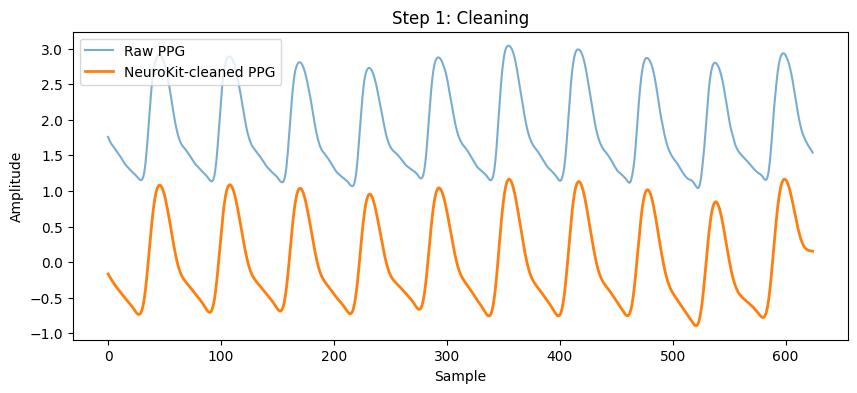

In [2]:
# Step 1: nk.ppg_clean()
# Filters the raw PPG (removes baseline wander and high-frequency noise), similar to
# our own Butterworth bandpass filter, but tuned specifically for PPG morphology.

ppg_clean = nk.ppg_clean(ppg_raw, sampling_rate=FS)

plt.figure(figsize=(10, 4))
plt.plot(ppg_raw, label='Raw PPG', alpha=0.6)
plt.plot(ppg_clean, label='NeuroKit-cleaned PPG', linewidth=2)
plt.title('Step 1: Cleaning')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.legend()
plt.show()

In [ ]:
# Step 2: nk.ppg_findpeaks()
# Detects the systolic peak of each pulse wave in the cleaned signal.
# This replaces a manual scipy.signal.find_peaks call with a detector tuned for PPG shape.

peaks = nk.ppg_findpeaks(ppg_clean, sampling_rate=FS)['PPG_Peaks']
print(f'Detected {len(peaks)} beats in this 5-second window')

plt.figure(figsize=(10, 4))
plt.plot(ppg_clean, label='Cleaned PPG')
plt.scatter(peaks, ppg_clean[peaks], color='red', zorder=5, label='Detected peaks')
plt.title('Step 2: Peak detection')
plt.xlabel('Sample')
plt.ylabel('Amplitude')
plt.legend()
plt.show()

In [ ]:
# Step 3: nk.ppg_quality()
# Builds an average pulse-wave template from the detected beats, then scores every
# sample by how well its beat correlates with that template (1 = matches perfectly,
# 0 = no correlation). A window full of low scores means the beats look inconsistent
# with each other -- a sign of motion artifact or noise rather than a clean pulse.
# This is what replaces our Welch spectral-ratio check in preprocess.ipynb.

quality = nk.ppg_quality(ppg_clean, peaks=peaks, sampling_rate=FS, method='templatematch')
print(f'Mean quality score for this window: {quality.mean():.3f}')

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(ppg_clean)
ax[0].set_title('Cleaned PPG')
ax[0].set_ylabel('Amplitude')

ax[1].plot(quality, color='green')
ax[1].set_title('Step 3: Per-sample quality score (template-match)')
ax[1].set_xlabel('Sample')
ax[1].set_ylabel('Quality (0-1)')
ax[1].set_ylim(0, 1.05)
plt.tight_layout()
plt.show()